# 06 Scaling

PLAN.md step 7: measured cost per stage (`results/benchmarks.csv`, from the last `--rebuild` run) and the projection to a 380-match season (`profiling.season_projection` -> `results/step7_scaling.csv`).

In [1]:
import pandas as pd
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"

## Raw benchmark rows (one per stage call)

In [2]:
pd.read_csv(RESULTS / "benchmarks.csv")

,timestamp,stage,match_id,wall_s,peak_mb,process_peak_mb,rows_in,rows_out
0,2026-11-05T15:13:31,load tracking -> long format,1.0,110.203,1874.3,5285.4,NaN,3278389.0
1,2026-11-05T15:13:31,"clean tracking (ID fixes, metres, flip, veloci...",1.0,0.419,364.0,5285.4,3278389.0,3278389.0
2,2026-11-05T15:13:33,write tracking parquet,1.0,1.307,147.5,5285.4,3278389.0,NaN
3,2026-11-05T15:15:18,load tracking -> long format,2.0,102.123,1786.2,5285.4,NaN,3188708.0
4,2026-11-05T15:15:18,"clean tracking (ID fixes, metres, flip, veloci...",2.0,0.358,354.0,5285.4,3188708.0,3188708.0
5,2026-11-05T15:15:19,write tracking parquet,2.0,1.102,143.5,5285.4,3188708.0,NaN
6,2026-11-05T15:18:43,load tracking -> long format,3.0,200.160,2315.4,6976.1,NaN,3260178.0
7,2026-11-05T15:18:43,"clean tracking (ID fixes, metres, flip, veloci...",3.0,0.384,361.9,6976.1,3260178.0,3260178.0
8,2026-11-05T15:18:45,write tracking parquet,3.0,1.518,146.7,6976.1,3260178.0,NaN
9,2026-11-05T15:18:46,read tracking at pass frames,1.0,0.259,0.6,6976.1,1059.0,24333.0


## Season projection (measured x 380 / 3)

In [3]:
scaling = pd.read_csv(RESULTS / "step7_scaling.csv", index_col=0)
scaling

,rows_out,wall_s,peak_mb,process_peak_mb,season_wall_min,season_parquet_gb
stage,,,,,,
load tracking -> long format,9727275.0,412.5,2315.4,6976.1,870.8,NaN
"clean tracking (ID fixes, metres, flip, velocities)",9727275.0,1.2,364.0,6976.1,2.5,NaN
write tracking parquet,0.0,3.9,147.5,6976.1,8.3,NaN
read tracking at pass frames,167347.0,0.5,0.6,6976.1,1.1,NaN
build passes (read pass frames only),3645.0,0.4,4.2,6976.1,0.9,NaN
build features (all folds),10893.0,0.7,21.3,6976.1,1.4,NaN
all stages,NaN,419.2,2315.4,6976.1,885.0,NaN
tracking Parquet on disk,9727275.0,NaN,NaN,NaN,NaN,21.6


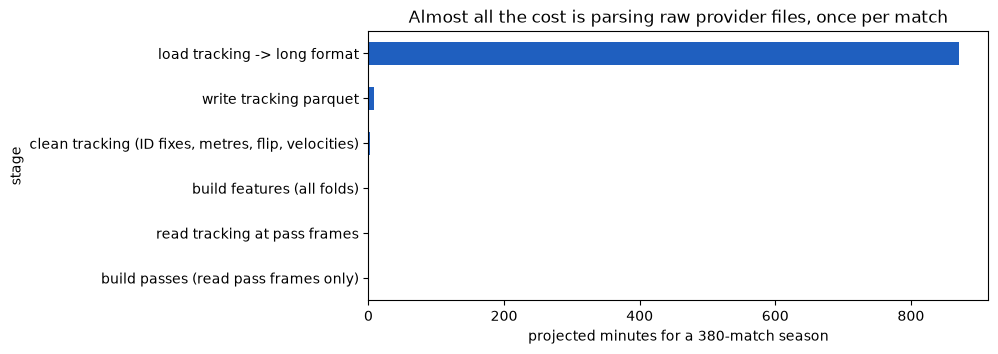

In [4]:
s = scaling["season_wall_min"].drop("all stages").dropna()
ax = s.sort_values().plot.barh(color="#1f5fbf", figsize=(8, 3.5))
ax.set_xlabel("projected minutes for a 380-match season")
ax.set_title("Almost all the cost is parsing raw provider files, once per match");

In [5]:
pd.read_csv(RESULTS / "tracking_files.csv")

,match_id,rows,parquet_mb,players_tracked,speed_capped_rows
0,1,3278389,57.5,28,285
1,2,3188708,56.0,26,868
2,3,3260178,57.0,35,363
